# 📊 Предиктивная аналитика и EDA (Для аналитиков)
Этот ноутбук демонстрирует работу Data-отдела. В то время как маркетологи используют UI-дашборды (Streamlit/Metabase), аналитики в Jupyter:
1. Устанавливают зависимости и подключаются к DWH (PostgreSQL).
2. Ищут скрытые закономерности (EDA, Корреляции).
3. Строят ML-модели для предсказания выручки.

In [2]:
# Установка драйвера БД (на случай, если контейнер был перезапущен)
!pip install psycopg2-binary -q
print("✅ Зависимости успешно установлены!")

✅ Зависимости успешно установлены!


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
import os
import warnings
warnings.filterwarnings('ignore')

# 1. ПОДКЛЮЧЕНИЕ К БАЗЕ ДАННЫХ
# Переменные окружения уже проброшены через docker-compose
DB_USER = os.getenv('DB_USER', 'market_admin')
DB_PASS = os.getenv('DB_PASS', 'supersecret_db_pass_2026')
DB_HOST = os.getenv('DB_HOST', 'postgres')
DB_NAME = os.getenv('DB_NAME', 'marketing_db')

engine = create_engine(f'postgresql://{DB_USER}:{DB_PASS}@{DB_HOST}:5432/{DB_NAME}')

# Выгрузка сырых данных
df = pd.read_sql('SELECT * FROM marketing_metrics', engine)
print(f"📥 Загружено {len(df)} записей из PostgreSQL. Первые строки:")
display(df.head())

📥 Загружено 1714 записей из PostgreSQL. Первые строки:


,id,campaign_name,date,impressions,clicks,conversions,spend,revenue
0,1,Email Promo Q3,2026-11-09,67535,1299,119,1390.00,16647.41
1,2,Meta Retargeting,2026-11-09,110319,5915,574,4737.97,22468.91
2,3,LinkedIn B2B,2026-11-09,49790,749,52,1071.12,4567.89
3,4,LinkedIn B2B,2026-11-09,20514,504,6,528.72,300.66
4,5,Meta Retargeting,2026-11-09,124955,5841,163,8377.78,13677.84


## 🔍 Шаг 1: Поиск зависимостей (Тепловая карта)
Аналитику важно доказать бизнесу, какие именно метрики стоит растить. Матрица корреляций показывает силу связи от -1 до 1.

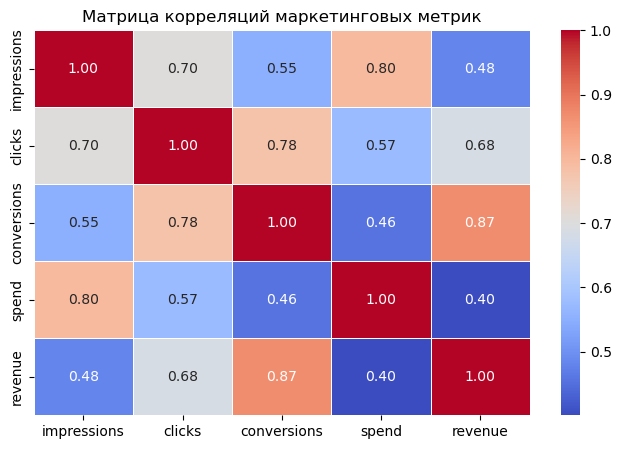

In [4]:
plt.figure(figsize=(8, 5))
numeric_cols = df[['impressions', 'clicks', 'conversions', 'spend', 'revenue']]
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Матрица корреляций маркетинговых метрик")
plt.show()

## 🤖 Шаг 2: Машинное обучение (Прогноз выручки)
Обучаем модель линейной регрессии, чтобы понимать, сколько выручки принесет каждый вложенный в рекламу доллар.

⚙️ Модель обучена! Точность аппроксимации (R²): 0.16


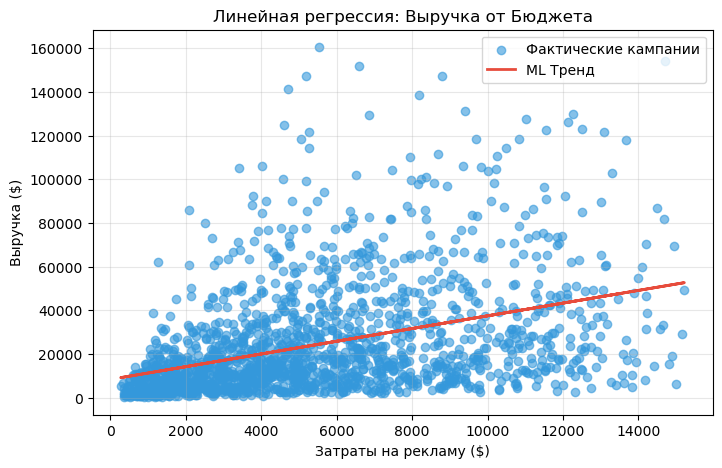

In [5]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Подготовка признаков (X - затраты, y - выручка)
X = df[['spend']]
y = df['revenue']

# Обучение модели
model = LinearRegression()
model.fit(X, y)
r_sq = model.score(X, y)

print(f"⚙️ Модель обучена! Точность аппроксимации (R²): {r_sq:.2f}")

# Визуализация модели
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='#3498db', alpha=0.6, label='Фактические кампании')
plt.plot(X, model.predict(X), color='#e74c3c', linewidth=2, label='ML Тренд')
plt.xlabel("Затраты на рекламу ($)")
plt.ylabel("Выручка ($)")
plt.title("Линейная регрессия: Выручка от Бюджета")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 🎯 Шаг 3: Симуляция What-If (Консольный вывод)
Это то, что можно обернуть в API для маркетологов. Мы вводим гипотетический бюджет и получаем прогноз.

In [6]:
# Задаем произвольный бюджет, которого еще не было в базе
simulated_budget = 45000  

predicted_revenue = model.predict(np.array([[simulated_budget]]))[0]
estimated_profit = predicted_revenue - simulated_budget

print("="*50)
print("🔮 РЕЗУЛЬТАТЫ ML-СИМУЛЯЦИИ")
print("="*50)
print(f"Инвестиции в рекламу:  ${simulated_budget:,.2f}")
print(f"Ожидаемая выручка:     ${predicted_revenue:,.2f}")
print("-"*50)
print(f"Прогнозируемая чистая прибыль: ${estimated_profit:,.2f}")
print("="*50)

🔮 РЕЗУЛЬТАТЫ ML-СИМУЛЯЦИИ
Инвестиции в рекламу:  $45,000.00
Ожидаемая выручка:     $139,265.90
--------------------------------------------------
Прогнозируемая чистая прибыль: $94,265.90
